In [1]:
from google.colab import files

uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

import scipy.cluster.hierarchy as sch

In [3]:
df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan 5 data pertama
display(df.head())

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [5]:
display(df.describe())

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nJumlah baris dan kolom:")
print(df.shape)

Missing Values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Jumlah baris dan kolom:
(660, 7)


In [7]:
# Identifikasi kolom ID
id_columns = [
    col for col in df.columns
    if any(key in col.lower().replace("_", "").replace(" ", "")
           for key in ["customerid", "customerkey", "custid"])
    or col.lower().replace("_", "").replace(" ", "") == "id"
]

# Menghapus kolom ID dari fitur
features_df = df.drop(columns=id_columns)

print("Kolom ID yang dikeluarkan:", id_columns)
print("\nVariabel yang digunakan:")
print(features_df.columns.tolist())

print("\nJumlah variabel:", len(features_df.columns))

Kolom ID yang dikeluarkan: ['Customer Key']

Variabel yang digunakan:
['Sl_No', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Jumlah variabel: 6


In [8]:
# Pisahkan kolom numerik dan kategorikal
numeric_cols = features_df.select_dtypes(include=np.number).columns
categorical_cols = features_df.select_dtypes(exclude=np.number).columns

# Mengisi missing values numerik menggunakan median
numeric_data = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(
        features_df[numeric_cols]
    ),
    columns=numeric_cols,
    index=features_df.index
)

# Mengisi missing values kategorikal menggunakan modus
if len(categorical_cols) > 0:
    categorical_data = features_df[categorical_cols].copy()

    for col in categorical_cols:
        categorical_data[col] = categorical_data[col].fillna(
            categorical_data[col].mode()[0]
        )

    features_df = pd.concat(
        [numeric_data, categorical_data],
        axis=1
    )
else:
    features_df = numeric_data

# Mengubah variabel kategorikal menjadi numerik jika ada
X_df = pd.get_dummies(features_df, drop_first=True, dtype=int)

# Menghapus fitur konstan yang tidak memberikan informasi
X_df = X_df.loc[:, X_df.nunique() > 1]

print("Fitur akhir yang digunakan:")
print(X_df.columns.tolist())

print("\nJumlah fitur akhir:", X_df.shape[1])

Fitur akhir yang digunakan:
['Sl_No', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Jumlah fitur akhir: 6


In [9]:
scaler = StandardScaler()

X = scaler.fit_transform(X_df)

print("Shape X:", X.shape)

Shape X: (660, 6)


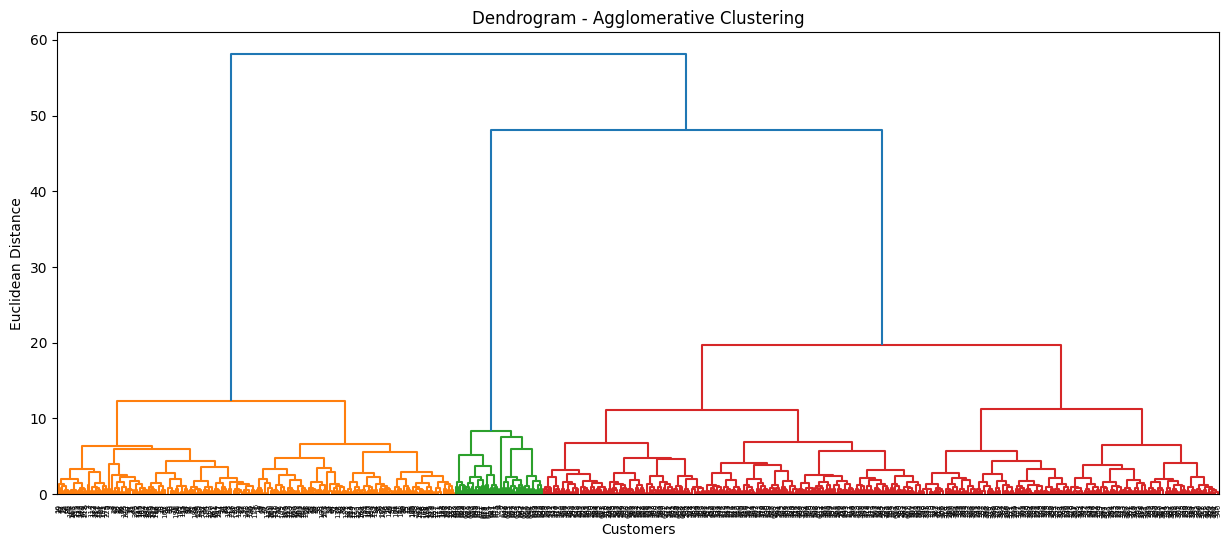

In [10]:
plt.figure(figsize=(15, 6))

dendrogram = sch.dendrogram(
    sch.linkage(X, method='ward')
)

plt.title('Dendrogram - Agglomerative Clustering')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')
plt.show()

In [11]:
results = []

for k in range(2, 11):

    hc = AgglomerativeClustering(
        n_clusters=k,
        metric='euclidean',
        linkage='ward'
    )

    labels = hc.fit_predict(X)

    sil_score = silhouette_score(X, labels)
    dbi_score = davies_bouldin_score(X, labels)

    results.append({
        'Number of Clusters': k,
        'Silhouette Score': sil_score,
        'Davies-Bouldin Index': dbi_score
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Number of Clusters,Silhouette Score,Davies-Bouldin Index
0,2,0.4453,0.8633
1,3,0.5305,0.6695
2,4,0.3766,1.0768
3,5,0.2679,1.3926
4,6,0.2389,1.3488
5,7,0.2346,1.4877
6,8,0.2115,1.6249
7,9,0.2152,1.4477
8,10,0.2033,1.4914


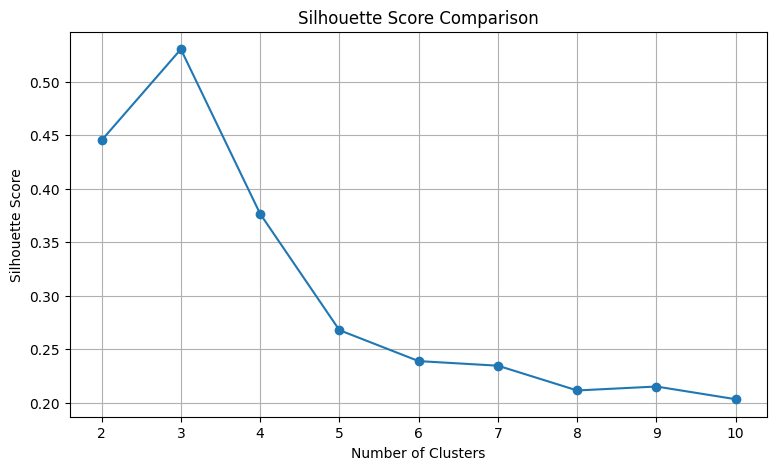

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Number of Clusters'],
    results_df['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Score Comparison')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

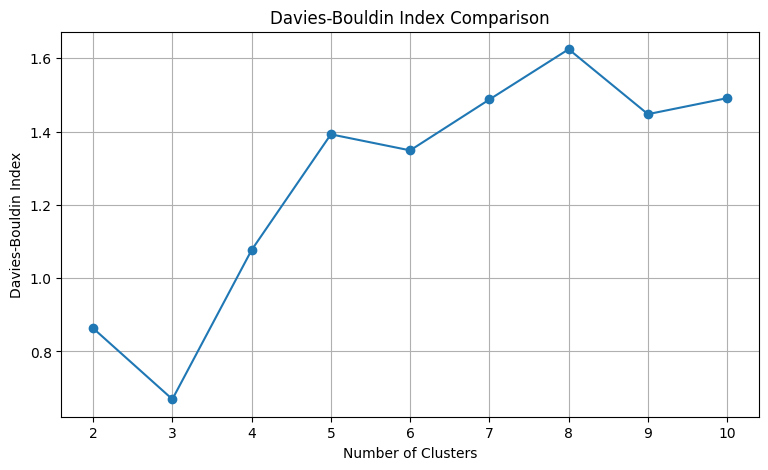

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Number of Clusters'],
    results_df['Davies-Bouldin Index'],
    marker='o'
)

plt.title('Davies-Bouldin Index Comparison')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Index')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

In [14]:
best_k = int(
    results_df.loc[
        results_df['Silhouette Score'].idxmax(),
        'Number of Clusters'
    ]
)

print("Jumlah cluster terpilih:", best_k)

Jumlah cluster terpilih: 3


In [15]:
hc = AgglomerativeClustering(
    n_clusters=best_k,
    metric='euclidean',
    linkage='ward'
)

y_hc = hc.fit_predict(X)

print("Clustering berhasil dilakukan!")
print("Jumlah cluster:", len(np.unique(y_hc)))

Clustering berhasil dilakukan!
Jumlah cluster: 3


In [16]:
cluster_counts = pd.Series(y_hc).value_counts().sort_index()

print("Jumlah anggota setiap cluster:")
display(cluster_counts)

Jumlah anggota setiap cluster:


,count
0,384
1,226
2,50


In [17]:
# Mencari nama kolom berdasarkan beberapa kemungkinan penulisan
def find_column(candidates):
    normalized_columns = {
        ''.join(c.lower().split()).replace('_', ''): c
        for c in df.columns
    }

    for candidate in candidates:
        key = ''.join(candidate.lower().split()).replace('_', '')

        if key in normalized_columns:
            return normalized_columns[key]

    raise ValueError(
        f"Kolom tidak ditemukan. Kolom tersedia: {df.columns.tolist()}"
    )


avg_col = find_column(['Avg_Credit_Limit'])

card_col = find_column([
    'Total_credit_card',
    'Total_Credit_Cards',
    'Total_credit_cards'
])

print("Variabel X:", avg_col)
print("Variabel Y:", card_col)

Variabel X: Avg_Credit_Limit
Variabel Y: Total_Credit_Cards


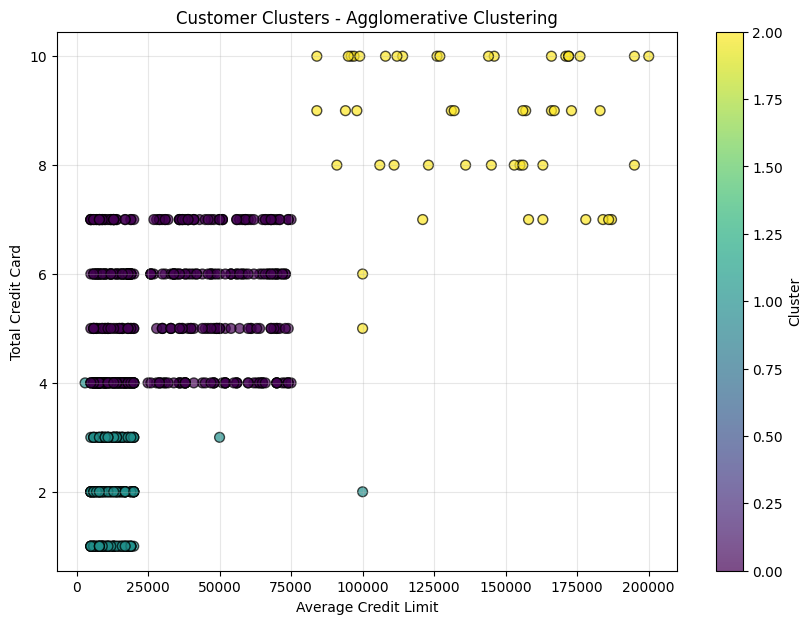

In [18]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df[avg_col],
    df[card_col],
    c=y_hc,
    cmap='viridis',
    s=50,
    alpha=0.7,
    edgecolors='black'
)

plt.title('Customer Clusters - Agglomerative Clustering')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Card')
plt.colorbar(scatter, label='Cluster')
plt.grid(alpha=0.3)

plt.show()

In [19]:
sil_score = silhouette_score(X, y_hc)

print(f'Silhouette Score: {sil_score:.4f}')

Silhouette Score: 0.5305


In [20]:
dbi_score = davies_bouldin_score(X, y_hc)

print(f'Davies-Bouldin Index: {dbi_score:.4f}')

Davies-Bouldin Index: 0.6695


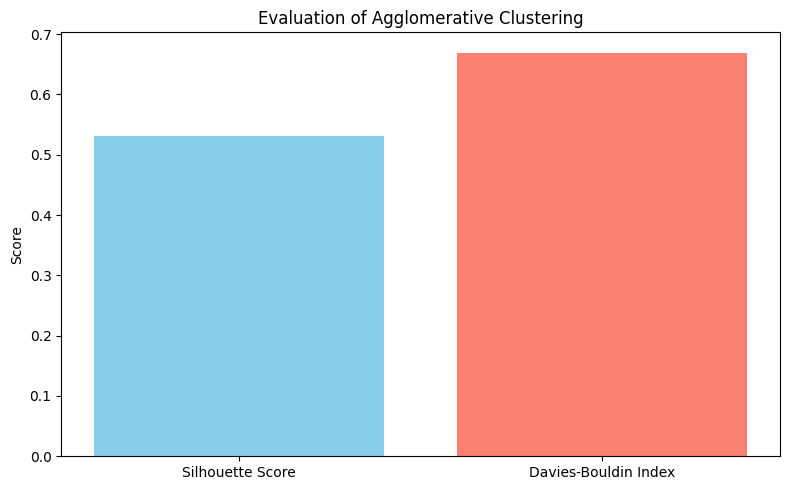

In [21]:
scores = {
    'Silhouette Score': sil_score,
    'Davies-Bouldin Index': dbi_score
}

plt.figure(figsize=(8, 5))

plt.bar(
    scores.keys(),
    scores.values(),
    color=['skyblue', 'salmon']
)

plt.title('Evaluation of Agglomerative Clustering')
plt.ylabel('Score')

plt.tight_layout()
plt.show()

In [22]:
print("===== AGGLOMERATIVE CLUSTERING RESULTS =====")

print(f"Total Customers       : {len(df)}")
print(f"Total Features        : {X.shape[1]}")
print(f"Number of Clusters    : {best_k}")
print(f"Silhouette Score      : {sil_score:.4f}")
print(f"Davies-Bouldin Index  : {dbi_score:.4f}")

print("\n===== CLUSTER DISTRIBUTION =====")
print(cluster_counts)

===== AGGLOMERATIVE CLUSTERING RESULTS =====
Total Customers       : 660
Total Features        : 6
Number of Clusters    : 3
Silhouette Score      : 0.5305
Davies-Bouldin Index  : 0.6695

===== CLUSTER DISTRIBUTION =====
0    384
1    226
2     50
Name: count, dtype: int64
